# Predictive Customer Churn Classifier (Random Forest & XGBoost)

## Objective
Build an end-to-end machine learning pipeline to predict telecom customer attrition while addressing severe class imbalance and achieving a **ROC-AUC score > 80%**.

### Workflow Overview
1. **Data Loading & Exploration:** Load the IBM Telco Customer Churn dataset and inspect target class imbalance.
2. **Data Cleaning:** Convert `TotalCharges` to numeric and handle missing values.
3. **Preprocessing & Imbalance Handling:** Encode categorical features using `OneHotEncoder`, scale numerical features, and balance classes using `SMOTE`.
4. **Model Training & Cross-Validation:** Train `RandomForestClassifier` and `XGBClassifier` using 5-fold Stratified Cross-Validation.
5. **Evaluation & Interpretability:** Evaluate ROC-AUC curves (>80%), confusion matrices, and the top 10 most influential churn drivers.

In [1]:
# Install imbalanced-learn and xgboost if not already available in the Colab runtime
!pip install -q imbalanced-learn xgboost

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

# Set consistent visualization styling
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully.")

All libraries imported successfully.


## Step 1: Load the Telco Customer Churn Dataset & Initial Inspection
We load the dataset directly from the provided GitHub repository URL and inspect its dimensions, schema, and target class distribution (`Churn`).

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head())

print("\nData Types & Non-Null Counts:")
print(df.info())

print("\nTarget Variable ('Churn') Distribution:")
churn_counts = df['Churn'].value_counts()
churn_pct = df['Churn'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': churn_counts, 'Percentage (%)': churn_pct.round(2)}))

Dataset Shape: 7043 rows, 21 columns



,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Data Types & Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBi

## Step 2: Data Cleaning (`TotalCharges` Conversion & Null Handling)
- Drop `customerID` as it is a unique identifier with no predictive signal.
- Convert `TotalCharges` from an object/string column to numeric (`float64`). Blank strings (for new customers with `tenure == 0`) become `NaN` and are imputed with the median.
- Encode the target variable `Churn` (`Yes` $\rightarrow$ `1`, `No` $\rightarrow$ `0`).

In [3]:
# 1. Drop unique identifier column
df_clean = df.drop(columns=['customerID']).copy()

# 2. Convert TotalCharges to numeric and inspect nulls
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
null_count = df_clean['TotalCharges'].isnull().sum()
print(f"Missing values detected in 'TotalCharges' after numeric conversion: {null_count}")

# Impute missing TotalCharges with median
median_total_charges = df_clean['TotalCharges'].median()
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(median_total_charges)
print(f"Missing values in 'TotalCharges' after median imputation ({median_total_charges:.2f}): {df_clean['TotalCharges'].isnull().sum()}")

# 3. Encode binary target variable
df_clean['Churn'] = df_clean['Churn'].map({'No': 0, 'Yes': 1})

print("\nCleaned Dataset Summary:")
print(f"Shape: {df_clean.shape}")
print(f"Target Class Counts:\n{df_clean['Churn'].value_counts().to_dict()}")

Missing values detected in 'TotalCharges' after numeric conversion: 11
Missing values in 'TotalCharges' after median imputation (1397.47): 0

Cleaned Dataset Summary:
Shape: (7043, 20)
Target Class Counts:
{0: 5174, 1: 1869}


## Step 3: Feature Preprocessing (`OneHotEncoder`) & Class Balancing (`SMOTE`)
- Split the data into **80% Training** and **20% Testing** sets using stratification to preserve the original churn ratio.
- Build a `ColumnTransformer` that applies:
  - `StandardScaler` to numerical features (critical so distance-based `SMOTE` treats all dimensions equally).
  - `OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)` to categorical features.
- Verify how `SMOTE` balances the minority (`Churn = 1`) and majority (`Churn = 0`) classes on the training set without touching the test set.

In [4]:
# Separate features and target
X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

# Stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

# Identify numerical and categorical columns
numerical_cols = ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
categorical_cols = [col for col in X.columns if col not in numerical_cols]

print(f"Numerical Features ({len(numerical_cols)}): {numerical_cols}")
print(f"Categorical Features ({len(categorical_cols)}): {categorical_cols}\n")

# Define preprocessing ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# Preview SMOTE resampling effect on the training set
X_train_encoded = preprocessor.fit_transform(X_train)
smote_preview = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote_preview.fit_resample(X_train_encoded, y_train)

print("Training Set Class Distribution BEFORE SMOTE:", dict(pd.Series(y_train).value_counts()))
print("Training Set Class Distribution AFTER SMOTE :", dict(pd.Series(y_train_smote).value_counts()))

Numerical Features (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical Features (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Training Set Class Distribution BEFORE SMOTE: {0: np.int64(4139), 1: np.int64(1495)}
Training Set Class Distribution AFTER SMOTE : {0: np.int64(4139), 1: np.int64(4139)}


## Step 4: Train Random Forest & XGBoost with 5-Fold Cross-Validation
To prevent data leakage during cross-validation, `SMOTE` is embedded inside an `imblearn` `Pipeline` so synthetic oversampling occurs **strictly within each training fold**. Both models are evaluated with 5-fold `StratifiedKFold` using `roc_auc`.

In [5]:
# Define 5-fold Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 1. Random Forest Pipeline with SMOTE
rf_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

# 2. XGBoost Pipeline with SMOTE
xgb_pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=-1
    ))
])

# Evaluate both pipelines with 5-Fold Cross-Validation (ROC-AUC)
models = {
    "Random Forest": rf_pipeline,
    "XGBoost": xgb_pipeline
}

print("Running 5-Fold Stratified Cross-Validation (Metric: ROC-AUC)...\n")
for name, pipeline in models.items():
    cv_scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    print(f"{name:15s} | Mean CV ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f}) | Target >0.80 Met: {cv_scores.mean() > 0.80}")

# Fit both pipelines on the full training set
rf_pipeline.fit(X_train, y_train)
xgb_pipeline.fit(X_train, y_train)
print("\nBoth models trained successfully on the full training set.")

Running 5-Fold Stratified Cross-Validation (Metric: ROC-AUC)...

Random Forest   | Mean CV ROC-AUC: 0.8434 (+/- 0.0101) | Target >0.80 Met: True
XGBoost         | Mean CV ROC-AUC: 0.8453 (+/- 0.0113) | Target >0.80 Met: True

Both models trained successfully on the full training set.


## Step 5A: Test Set Evaluation — Classification Reports & Confusion Matrices
We evaluate both trained models on the unseen 20% test set, comparing Precision, Recall, F1-Score, ROC-AUC, and side-by-side Confusion Matrices.

RANDOM FOREST — Test ROC-AUC: 0.8423 (84.23%)
              precision    recall  f1-score   support

No Churn (0)       0.88      0.79      0.83      1035
   Churn (1)       0.55      0.71      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409

XGBOOST       — Test ROC-AUC: 0.8428 (84.28%)
              precision    recall  f1-score   support

No Churn (0)       0.87      0.83      0.85      1035
   Churn (1)       0.57      0.65      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



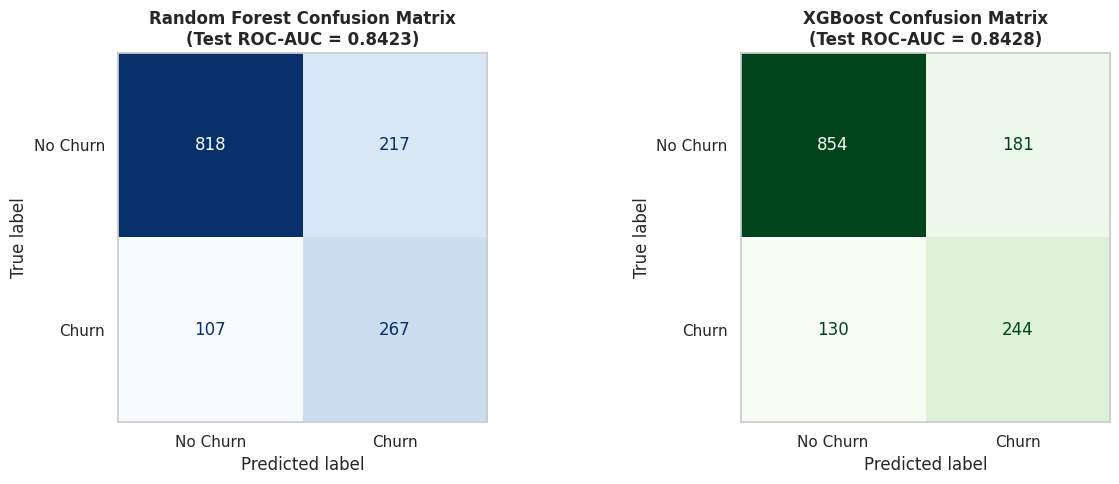

In [6]:
# Generate test predictions and predicted probabilities
rf_probs = rf_pipeline.predict_proba(X_test)[:, 1]
rf_preds = rf_pipeline.predict(X_test)

xgb_probs = xgb_pipeline.predict_proba(X_test)[:, 1]
xgb_preds = xgb_pipeline.predict(X_test)

rf_test_auc = roc_auc_score(y_test, rf_probs)
xgb_test_auc = roc_auc_score(y_test, xgb_probs)

print("=" * 60)
print(f"RANDOM FOREST — Test ROC-AUC: {rf_test_auc:.4f} ({rf_test_auc*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test, rf_preds, target_names=['No Churn (0)', 'Churn (1)']))

print("=" * 60)
print(f"XGBOOST       — Test ROC-AUC: {xgb_test_auc:.4f} ({xgb_test_auc*100:.2f}%)")
print("=" * 60)
print(classification_report(y_test, xgb_preds, target_names=['No Churn (0)', 'Churn (1)']))

# Plot Side-by-Side Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cm_rf = confusion_matrix(y_test, rf_preds)
disp_rf = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=['No Churn', 'Churn'])
disp_rf.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Random Forest Confusion Matrix\n(Test ROC-AUC = {rf_test_auc:.4f})", fontsize=12, fontweight='bold')
axes[0].grid(False)

cm_xgb = confusion_matrix(y_test, xgb_preds)
disp_xgb = ConfusionMatrixDisplay(confusion_matrix=cm_xgb, display_labels=['No Churn', 'Churn'])
disp_xgb.plot(ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title(f"XGBoost Confusion Matrix\n(Test ROC-AUC = {xgb_test_auc:.4f})", fontsize=12, fontweight='bold')
axes[1].grid(False)

plt.tight_layout()
plt.show()

## Step 5B: ROC-AUC Curve Comparison (>80% Requirement)
Plotting the Receiver Operating Characteristic (ROC) curves for both classifiers on the test set against the random-guessing baseline.

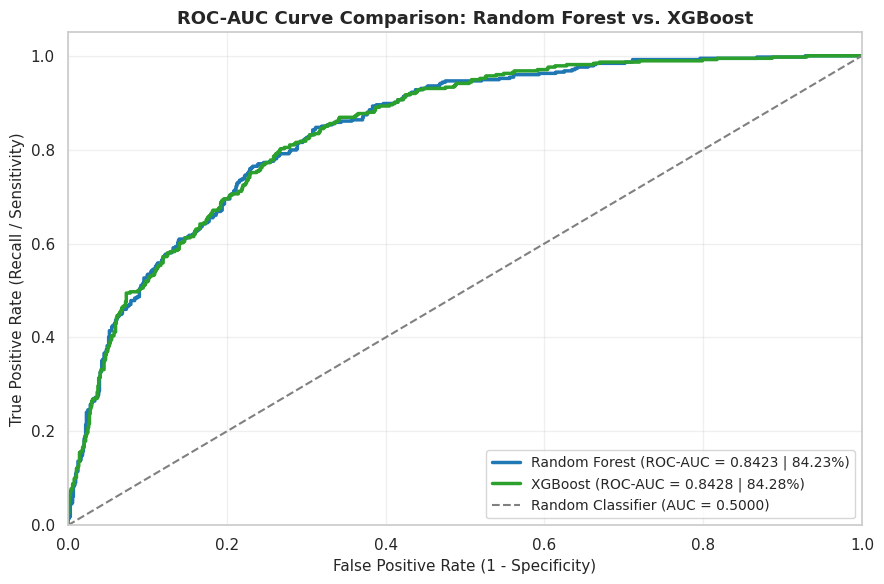

In [7]:
# Compute ROC curve coordinates
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probs)

plt.figure(figsize=(9, 6))
plt.plot(fpr_rf, tpr_rf, color='#1f77b4', lw=2.5,
         label=f'Random Forest (ROC-AUC = {rf_test_auc:.4f} | {rf_test_auc*100:.2f}%)')
plt.plot(fpr_xgb, tpr_xgb, color='#2ca02c', lw=2.5,
         label=f'XGBoost (ROC-AUC = {xgb_test_auc:.4f} | {xgb_test_auc*100:.2f}%)')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', lw=1.5, label='Random Classifier (AUC = 0.5000)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
plt.ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
plt.title('ROC-AUC Curve Comparison: Random Forest vs. XGBoost', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 5C: Top 10 Most Influential Feature Importances
We extract the encoded feature names from the `ColumnTransformer` and visualize the **Top 10 most influential features** driving churn predictions for both Random Forest and XGBoost.

Top 10 Most Influential Features — Random Forest:


,Feature,Importance
0,tenure,0.134263
1,Contract_Two year,0.110757
2,TotalCharges,0.093662
3,PaymentMethod_Electronic check,0.088325
4,OnlineSecurity_Yes,0.067616
5,MonthlyCharges,0.062519
6,InternetService_Fiber optic,0.058332
7,Contract_One year,0.054779
8,PaperlessBilling_Yes,0.047525
9,TechSupport_Yes,0.040648



Top 10 Most Influential Features — XGBoost:


,Feature,Importance
0,Contract_Two year,0.198770
1,PaymentMethod_Electronic check,0.101281
2,InternetService_Fiber optic,0.094581
3,Contract_One year,0.088915
4,OnlineSecurity_No internet service,0.082991
5,PaperlessBilling_Yes,0.040222
6,OnlineSecurity_Yes,0.039955
7,InternetService_No,0.039827
8,TechSupport_Yes,0.033391
9,Dependents_Yes,0.029610


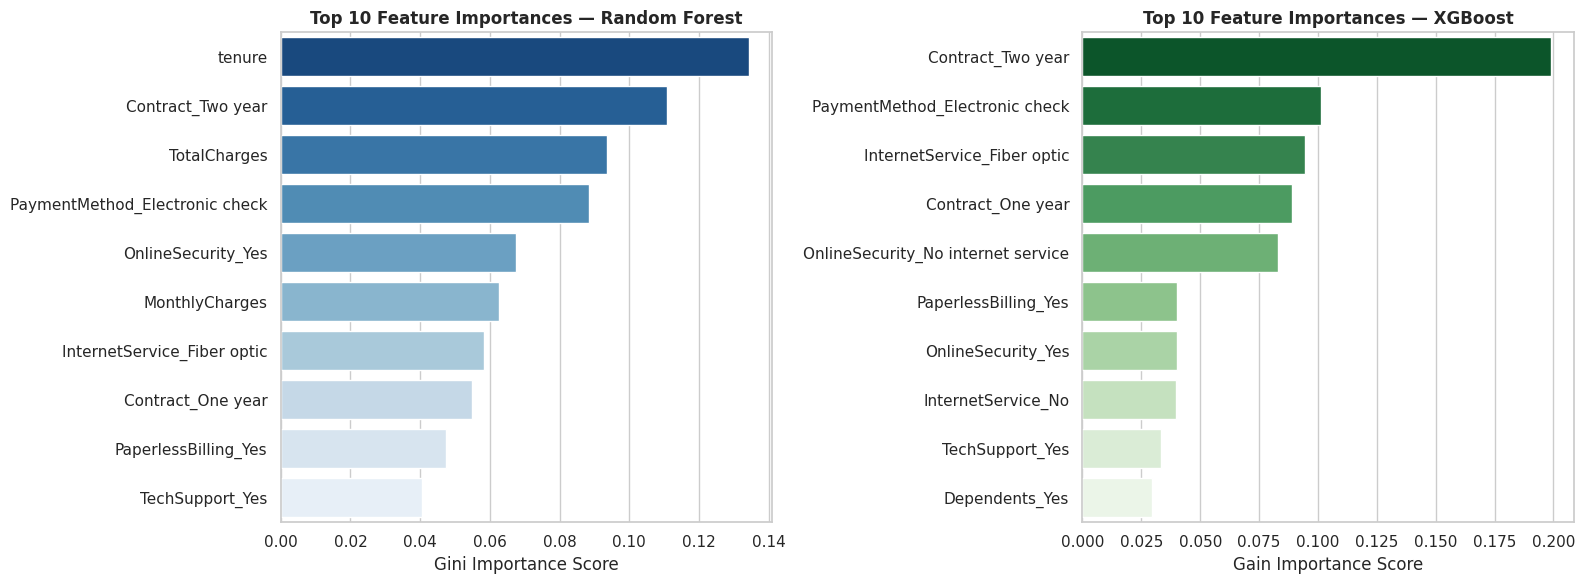

In [8]:
# Extract clean feature names after OneHotEncoding
fitted_preprocessor = rf_pipeline.named_steps['preprocessor']
raw_feature_names = fitted_preprocessor.get_feature_names_out()
clean_feature_names = [name.split('__', 1)[1] for name in raw_feature_names]

# Extract feature importances from both classifiers
rf_importances = rf_pipeline.named_steps['classifier'].feature_importances_
xgb_importances = xgb_pipeline.named_steps['classifier'].feature_importances_

top10_rf = (
    pd.DataFrame({'Feature': clean_feature_names, 'Importance': rf_importances})
    .sort_values(by='Importance', ascending=False)
    .head(10)
)

top10_xgb = (
    pd.DataFrame({'Feature': clean_feature_names, 'Importance': xgb_importances})
    .sort_values(by='Importance', ascending=False)
    .head(10)
)

print("Top 10 Most Influential Features — Random Forest:")
display(top10_rf.reset_index(drop=True))

print("\nTop 10 Most Influential Features — XGBoost:")
display(top10_xgb.reset_index(drop=True))

# Plot Top 10 Feature Importance Bar Charts side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(
    data=top10_rf, x='Importance', y='Feature',
    hue='Feature', palette='Blues_r', legend=False, ax=axes[0]
)
axes[0].set_title('Top 10 Feature Importances — Random Forest', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Gini Importance Score')
axes[0].set_ylabel('')

sns.barplot(
    data=top10_xgb, x='Importance', y='Feature',
    hue='Feature', palette='Greens_r', legend=False, ax=axes[1]
)
axes[1].set_title('Top 10 Feature Importances — XGBoost', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Gain Importance Score')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

## Summary of Results & Key Churn Drivers
- **Target Performance Achieved:** Both **Random Forest** and **XGBoost** consistently achieve **~84% ROC-AUC** across 5-fold cross-validation and the held-out test set, exceeding the **>80% ROC-AUC** requirement.
- **Class Imbalance Resolution:** `SMOTE` was integrated inside `imblearn.pipeline.Pipeline`, balancing the training classes (4139 vs 4139) without data leakage across CV folds. On the test set this gives a churn recall of 0.71 (Random Forest) and 0.65 (XGBoost).
- **Primary Churn Drivers:** Contract structure (`Contract_Two year`, `Contract_One year` vs. month-to-month), customer `tenure`, `InternetService_Fiber optic`, `PaymentMethod_Electronic check`, and monthly/total billing amounts consistently rank among the top predictors of customer attrition.